### **Conexion del drive e instalación de librerías**

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

!pip install -q ultralytics torchinfo scikit-learn pandas


Mounted at /content/drive


### **Partición física única estratificada (70% train / 25% test / 5% val)**

In [2]:
import os
import shutil
from sklearn.model_selection import train_test_split

ruta_origen = "/content/drive/MyDrive/dataset_balanceado"
ruta_destino = "/content/ecg_yolo_dataset"

if os.path.exists(ruta_destino):
    shutil.rmtree(ruta_destino)

clases = sorted([d for d in os.listdir(ruta_origen) if os.path.isdir(os.path.join(ruta_origen, d))])

for clase in clases:
    carpeta_clase = os.path.join(ruta_origen, clase)
    imagenes = sorted([f for f in os.listdir(carpeta_clase) if f.lower().endswith(".png")])

    train_imgs, temp_imgs = train_test_split(imagenes, test_size=0.30, random_state=42)
    test_imgs, val_imgs = train_test_split(temp_imgs, test_size=(5/30), random_state=42)

    particiones = {"train": train_imgs, "test": test_imgs, "val": val_imgs}

    for split, lista_archivos in particiones.items():
        destino_split = os.path.join(ruta_destino, split, clase)
        os.makedirs(destino_split, exist_ok=True)
        for archivo in lista_archivos:
            shutil.copy2(os.path.join(carpeta_clase, archivo), os.path.join(destino_split, archivo))

print("Partición 70/25/5 creada en:", ruta_destino)
for split in ["train", "test", "val"]:
    total = sum(len(os.listdir(os.path.join(ruta_destino, split, c))) for c in clases)
    print(f"  - {split}: {total} imágenes")


Partición 70/25/5 creada en: /content/ecg_yolo_dataset
  - train: 357 imágenes
  - test: 129 imágenes
  - val: 27 imágenes


### **Modelo 1 — Red Híbrida (MobileNetV2 + Custom CNN) con las 5 semillas y exportación a CSV**

**Origen y Referencia del Modelo Híbrido**
El diseño de esta arquitectura liviana y personalizada está basado en la siguiente publicación científica:

> **Referencia:**
> M. A. H. Rafi, S. Sharma, M. M. Islam, N. Islam and P. Bhowmik, "*ECG-Based Cardiac Abnormality Identification with Customized Hybrid Lightweight Architecture*," 2025 IEEE International Conference on Biomedical Engineering, Computer and Information Technology for Health (BECITHCON), Dhaka, Bangladesh, 2025, pp. 112-117, doi: [10.1109/BECITHCON69222.2025.11504126](https://doi.org/10.1109/BECITHCON69222.2025.11504126).

In [3]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

class ContrastEnhance:
    """Ajuste de contraste lineal previo a la normalización (alpha = 1.5)."""
    def __init__(self, alpha: float = 1.5):
        self.alpha = alpha

    def __call__(self, img: Image.Image) -> Image.Image:
        img = img.convert("RGB").resize((300, 300))
        return transforms.functional.adjust_contrast(img, self.alpha)

def get_transforms(train: bool = True):
    imagenet_mean = [0.485, 0.456, 0.406]
    imagenet_std = [0.229, 0.224, 0.225]

    ops = [ContrastEnhance(alpha=1.5)]
    if train:
        ops.extend([
            transforms.RandomRotation(degrees=(-5, 5)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
            transforms.ColorJitter(brightness=0.1, contrast=0.1),
        ])
    ops.extend([
        transforms.ToTensor(),
        transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
    ])
    return transforms.Compose(ops)

class CustomECGBranch(nn.Module):
    """Rama convolucional personalizada con 3 bloques: 32, 64 y 128 filtros."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.features(x)

class HybridMobileNetECG(nn.Module):
    """Arquitectura híbrida: MobileNetV2 + Rama CNN personalizada (32, 64, 128)."""
    def __init__(self, num_classes: int = 3, pretrained: bool = True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        mobilenet = models.mobilenet_v2(weights=weights)

        self.backbone = mobilenet.features
        self.backbone_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.ecg_branch = CustomECGBranch()
        fused_dim = 1280 + 128

        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, 512, bias=False),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),

            nn.Linear(512, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),

            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mob_feat = self.backbone(x)
        mob_vec = self.backbone_pool(mob_feat).flatten(1)
        ecg_vec = self.ecg_branch(x)
        fused = torch.cat([mob_vec, ecg_vec], dim=1)
        return self.classifier(fused)

In [6]:
import os
import time
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import f1_score, accuracy_score

# 1. Dataset de Imágenes que usa el pipeline de transformaciones híbrido
class ECGHybridDataset(Dataset):
    def __init__(self, ruta_split, transform=None):
        self.clases = sorted([d for d in os.listdir(ruta_split) if os.path.isdir(os.path.join(ruta_split, d))])
        self.class_to_idx = {clase: i for i, clase in enumerate(self.clases)}
        self.imagenes = []
        self.transform = transform
        for clase in self.clases:
            ruta_clase = os.path.join(ruta_split, clase)
            for archivo in sorted(os.listdir(ruta_clase)):
                if archivo.lower().endswith('.png'):
                    self.imagenes.append((os.path.join(ruta_clase, archivo), self.class_to_idx[clase]))

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, idx):
        ruta_img, etiqueta = self.imagenes[idx]
        img = Image.open(ruta_img)
        if self.transform:
            img = self.transform(img)
        return img, etiqueta

# 2. Configuración general
ruta_dataset = "/content/ecg_yolo_dataset"
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
batch_size = 16
lr = 0.001
num_epochs = 50
semillas = [42, 101, 202, 303, 404]

os.makedirs("/content/drive/MyDrive/ecg_models", exist_ok=True)
resultados_hibrido = []

# Datasets cargando desde la ruta física configurada con sus transformaciones específicas
train_set = ECGHybridDataset(os.path.join(ruta_dataset, "train"), transform=get_transforms(train=True))
val_set = ECGHybridDataset(os.path.join(ruta_dataset, "val"), transform=get_transforms(train=False))
test_set = ECGHybridDataset(os.path.join(ruta_dataset, "test"), transform=get_transforms(train=False))

classes_num = len(train_set.clases)

# 3. Entrenamiento Multi-semilla
for seed in semillas:
    print(f"\nEntrenando Modelo Híbrido | Semilla: {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

    model = HybridMobileNetECG(num_classes=classes_num, pretrained=True).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_acc = 0.0
    best_epoch = 0
    best_path = f"/content/drive/MyDrive/ecg_models/hybrid_seed_{seed}_best.pt"

    t0_train = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()

        # Evaluación en validación para guardar los mejores pesos
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                preds = torch.argmax(model(x), dim=1)
                val_correct += (preds == y).sum().item()
                val_total += y.size(0)
        val_acc = val_correct / val_total

        if val_acc >= best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            torch.save(model.state_dict(), best_path)

    tiempo_train = time.time() - t0_train

    # Evaluación final con el mejor modelo en el set de prueba (Test)
    model.load_state_dict(torch.load(best_path))
    model.eval()
    y_true, y_pred, latencias_ms = [], [], []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            t0 = time.perf_counter()
            out = model(x)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t1 = time.perf_counter()

            latencias_ms.append(((t1 - t0) * 1000) / x.size(0))
            y_pred.extend(torch.argmax(out, dim=1).cpu().numpy())
            y_true.extend(y.numpy())

    f1_m = f1_score(y_true, y_pred, average="macro")
    acc = accuracy_score(y_true, y_pred)
    print(f"Mejor época: {best_epoch} | Test Accuracy: {acc*100:.2f}% | F1 Macro: {f1_m:.4f}")

    resultados_hibrido.append({
        "modelo": "Híbrido (MobileNet+CNN)",
        "semilla": seed,
        "epoca_final": best_epoch,
        "f1_macro": round(f1_m, 4),
        "accuracy": round(acc, 4),
        "tiempo_entrenamiento_s": round(tiempo_train, 2),
        "latencia_ms_por_img": round(np.mean(latencias_ms), 4)
    })

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

df_hybrid = pd.DataFrame(resultados_hibrido)
df_hybrid.to_csv("/content/drive/MyDrive/ecg_models/resultados_hybrid_5_semillas.csv", index=False)
print("\nRESUMEN MODELO HÍBRIDO:")
print(df_hybrid)


Entrenando Modelo Híbrido | Semilla: 42
Mejor época: 43 | Test Accuracy: 98.45% | F1 Macro: 0.9845

Entrenando Modelo Híbrido | Semilla: 101
Mejor época: 46 | Test Accuracy: 96.12% | F1 Macro: 0.9609

Entrenando Modelo Híbrido | Semilla: 202
Mejor época: 50 | Test Accuracy: 96.90% | F1 Macro: 0.9691

Entrenando Modelo Híbrido | Semilla: 303
Mejor época: 49 | Test Accuracy: 98.45% | F1 Macro: 0.9845

Entrenando Modelo Híbrido | Semilla: 404
Mejor época: 47 | Test Accuracy: 93.80% | F1 Macro: 0.9378

RESUMEN MODELO HÍBRIDO:
                    modelo  semilla  epoca_final  f1_macro  accuracy  \
0  Híbrido (MobileNet+CNN)       42           43    0.9845    0.9845   
1  Híbrido (MobileNet+CNN)      101           46    0.9609    0.9612   
2  Híbrido (MobileNet+CNN)      202           50    0.9691    0.9690   
3  Híbrido (MobileNet+CNN)      303           49    0.9845    0.9845   
4  Híbrido (MobileNet+CNN)      404           47    0.9378    0.9380   

   tiempo_entrenamiento_s  latencia_ms

### **Modelo 2 — BNN (ECG_XNOR_Ori) con 5 semillas y exportación a CSV**

**Origen y Referencia de la Red Binarizada (BNN)**
La implementación del pipeline de binarización y el concepto base de la red ECG_XNOR están basados en la siguiente implementación de código abierto de GitHub:

> **Repositorio de Origen:**
> [ECG_BNN_Net (xpww)](https://github.com/xpww/ECG_BNN_Net)

In [7]:
import sys
import os
import time
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import f1_score, accuracy_score

ruta_proyecto_drive = '/content/drive/MyDrive/'
if ruta_proyecto_drive not in sys.path:
    sys.path.append(ruta_proyecto_drive)

# Importamos la función de binarización original del repositorio
from utils.OP import BinarizeF

# 1. Dataset 2D real (sin aplanar la imagen)
class ECGImage2DDataset(Dataset):
    def __init__(self, ruta_split):
        self.clases = sorted([d for d in os.listdir(ruta_split) if os.path.isdir(os.path.join(ruta_split, d))])
        self.class_to_idx = {clase: i for i, clase in enumerate(self.clases)}
        self.imagenes = []
        for clase in self.clases:
            ruta_clase = os.path.join(ruta_split, clase)
            for archivo in sorted(os.listdir(ruta_clase)):
                if archivo.lower().endswith('.png'):
                    self.imagenes.append((os.path.join(ruta_clase, archivo), self.class_to_idx[clase]))

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, idx):
        ruta_img, etiqueta = self.imagenes[idx]
        img = Image.open(ruta_img).convert('L').resize((128, 128))
        tensor_2d = transforms.ToTensor()(img)  # Forma [1, 128, 128]
        tensor_2d = (tensor_2d - 0.5) / 0.5
        return tensor_2d, etiqueta

# 2. Capa Convolucional Binaria 2D usando BinarizeF de utils/OP.py
class BinaryConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0, binarize_input=True):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, bias=False)
        self.binarize_input = binarize_input

    def forward(self, x):
        if self.binarize_input:
            x = BinarizeF.apply(x)
        # Binarizar pesos con factor de escala medio (estilo XNOR-Net)
        w = self.conv.weight
        alpha = w.abs().mean(dim=(1, 2, 3), keepdim=True)
        w_bin = BinarizeF.apply(w) * alpha
        return F.conv2d(x, w_bin, stride=self.conv.stride, padding=self.conv.padding)

# 3. Arquitectura ECG_XNOR_Ori adaptada a 2D (6 bloques convolucionales binarios)
class ECG_XNOR_2D(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        # Bloque 1 mantiene entrada en precisión real (igual que block1 en ECG_XNOR_Ori)
        self.block1 = nn.Sequential(
            BinaryConv2d(1, 16, kernel_size=5, stride=2, padding=2, binarize_input=False),
            nn.MaxPool2d(2, 2),
            nn.PReLU(),
            nn.BatchNorm2d(16)
        )
        # Bloques 2 a 6 totalmente binarizados (pesos y activaciones)
        self.block2 = self._make_block(16, 32)
        self.block3 = self._make_block(32, 64)
        self.block4 = self._make_block(64, 64)
        self.block5 = self._make_block(64, 128)

        self.dropout = nn.Dropout(0.3)
        self.pool_global = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def _make_block(self, in_c, out_c):
        return nn.Sequential(
            BinaryConv2d(in_c, out_c, kernel_size=3, stride=1, padding=1, binarize_input=True),
            nn.MaxPool2d(2, 2),
            nn.PReLU(),
            nn.BatchNorm2d(out_c)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.pool_global(x).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

# 4. Entrenamiento y evaluación con las 5 semillas guardando el mejor modelo (best.pt)
ruta_dataset = "/content/ecg_yolo_dataset"
train_set = ECGImage2DDataset(os.path.join(ruta_dataset, "train"))
val_set = ECGImage2DDataset(os.path.join(ruta_dataset, "val"))
test_set = ECGImage2DDataset(os.path.join(ruta_dataset, "test"))

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
classes_num = len(train_set.clases)
batch_size = 16
lr = 0.001
num_epochs = 50
semillas = [42, 101, 202, 303, 404]

os.makedirs("/content/drive/MyDrive/ecg_models", exist_ok=True)
resultados_bnn = []

for seed in semillas:
    print(f"\nEntrenando BNN-2D (ECG_XNOR_2D) | Semilla: {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

    model = ECG_XNOR_2D(num_classes=classes_num).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_acc = 0.0
    best_epoch = 0
    best_path = f"/content/drive/MyDrive/ecg_models/bnn2d_seed_{seed}_best.pt"

    t0_train = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            # Mantener pesos latentes acotados en [-1, 1] (regla de BNN)
            for p in model.parameters():
                if p.ndim == 4:
                    p.data.clamp_(-1.0, 1.0)

        # Evaluar en validación para guardar el mejor modelo
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                preds = torch.argmax(model(x), dim=1)
                val_correct += (preds == y).sum().item()
                val_total += y.size(0)
        val_acc = val_correct / val_total

        if val_acc >= best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            torch.save(model.state_dict(), best_path)

    tiempo_train = time.time() - t0_train

    # Cargar el mejor modelo guardado y evaluar en Test
    model.load_state_dict(torch.load(best_path))
    model.eval()
    y_true, y_pred, latencias_ms = [], [], []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            t0 = time.perf_counter()
            out = model(x)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t1 = time.perf_counter()

            latencias_ms.append(((t1 - t0) * 1000) / x.size(0))
            y_pred.extend(torch.argmax(out, dim=1).cpu().numpy())
            y_true.extend(y.numpy())

    f1_m = f1_score(y_true, y_pred, average="macro")
    acc = accuracy_score(y_true, y_pred)
    print(f"Mejor época: {best_epoch} | Test Accuracy: {acc*100:.2f}% | F1 Macro: {f1_m:.4f}")

    resultados_bnn.append({
        "modelo": "ECG_XNOR_2D (BNN)",
        "semilla": seed,
        "epoca_final": best_epoch,
        "f1_macro": round(f1_m, 4),
        "accuracy": round(acc, 4),
        "tiempo_entrenamiento_s": round(tiempo_train, 2),
        "latencia_ms_por_img": round(np.mean(latencias_ms), 4)
    })

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

df_bnn = pd.DataFrame(resultados_bnn)
df_bnn.to_csv("/content/drive/MyDrive/ecg_models/resultados_bnn_5_semillas.csv", index=False)
print("\nRESUMEN BNN-2D:")
print(df_bnn)



Entrenando BNN-2D (ECG_XNOR_2D) | Semilla: 42
Mejor época: 44 | Test Accuracy: 82.95% | F1 Macro: 0.8226

Entrenando BNN-2D (ECG_XNOR_2D) | Semilla: 101
Mejor época: 27 | Test Accuracy: 79.07% | F1 Macro: 0.7873

Entrenando BNN-2D (ECG_XNOR_2D) | Semilla: 202
Mejor época: 18 | Test Accuracy: 62.79% | F1 Macro: 0.6024

Entrenando BNN-2D (ECG_XNOR_2D) | Semilla: 303
Mejor época: 43 | Test Accuracy: 59.69% | F1 Macro: 0.5767

Entrenando BNN-2D (ECG_XNOR_2D) | Semilla: 404
Mejor época: 38 | Test Accuracy: 60.47% | F1 Macro: 0.4909

RESUMEN BNN-2D:
              modelo  semilla  epoca_final  f1_macro  accuracy  \
0  ECG_XNOR_2D (BNN)       42           44    0.8226    0.8295   
1  ECG_XNOR_2D (BNN)      101           27    0.7873    0.7907   
2  ECG_XNOR_2D (BNN)      202           18    0.6024    0.6279   
3  ECG_XNOR_2D (BNN)      303           43    0.5767    0.5969   
4  ECG_XNOR_2D (BNN)      404           38    0.4909    0.6047   

   tiempo_entrenamiento_s  latencia_ms_por_img  
0  

### **Modelo 3 — YOLO (yolo11n-cls.pt) con las mismas 5 semillas y exportación a CSV**

**Origen y Referencia de YOLO11n-cls**
La implementación del modelo YOLO de clasificación, así como los pesos preentrenados cargados, provienen de la librería oficial de Ultralytics:

> **Repositorio de Origen:**
> [Ultralytics YOLO (yolo11n-cls.pt)](https://github.com/ultralytics/ultralytics)

In [8]:
import os
import time
import gc
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score
from ultralytics import YOLO

ruta_dataset = "/content/ecg_yolo_dataset"
semillas = [42, 101, 202, 303, 404]
resultados_yolo = []

clases = sorted(os.listdir(os.path.join(ruta_dataset, "test")))
test_paths, y_true = [], []
for idx, c in enumerate(clases):
    carpeta = os.path.join(ruta_dataset, "test", c)
    for f in sorted(os.listdir(carpeta)):
        if f.lower().endswith(".png"):
            test_paths.append(os.path.join(carpeta, f))
            y_true.append(idx)

for seed in semillas:
    print(f"\nEntrenando YOLO11n-cls | Semilla: {seed}")
    model = YOLO("yolo11n-cls.pt")

    t0_train = time.time()
    model.train(
        data=ruta_dataset,
        epochs=50,
        imgsz=128,
        batch=16,
        optimizer="Adam",
        lr0=0.001,
        patience=10,
        seed=seed,
        deterministic=True,
        device=0,
        fliplr=0.0,
        flipud=0.0,
        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.15,
        degrees=0.0,
        translate=0.0,
        scale=0.0,
        shear=0.0,
        perspective=0.0,
        mosaic=0.0,
        erasing=0.0,
        project="/content/drive/MyDrive/ecg_models",
        name=f"ECG_YOLO_seed_{seed}",
        exist_ok=True,
        verbose=False
    )
    tiempo_train = time.time() - t0_train

    best_model = YOLO(f"/content/drive/MyDrive/ecg_models/ECG_YOLO_seed_{seed}/weights/best.pt")

    y_pred, latencias_ms = [], []
    for img_path in test_paths:
        t0 = time.perf_counter()
        pred = best_model.predict(img_path, imgsz=128, device=0, verbose=False)[0]
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t1 = time.perf_counter()

        latencias_ms.append((t1 - t0) * 1000)
        y_pred.append(pred.probs.top1)

    resultados_yolo.append({
        "modelo": "YOLO11n-cls",
        "semilla": seed,
        "epoca_final": 50,
        "f1_macro": round(f1_score(y_true, y_pred, average="macro"), 4),
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "tiempo_entrenamiento_s": round(tiempo_train, 2),
        "latencia_ms_por_img": round(np.mean(latencias_ms), 4)
    })

    del model, best_model
    gc.collect()
    torch.cuda.empty_cache()

df_yolo = pd.DataFrame(resultados_yolo)
df_yolo.to_csv("/content/drive/MyDrive/ecg_models/resultados_yolo_5_semillas.csv", index=False)
print("\nRESUMEN YOLO:")
print(df_yolo)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

Entrenando YOLO11n-cls | Semilla: 42
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ecg_yolo_dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, f

### **Diagrama Comparativo Multidimensional de los Tres Métodos**

Este gráfico compara de forma visual las tres métricas críticas de rendimiento para cada modelo evaluado con las 5 semillas:
1. **Precisión (F1-Macro):** Calidad diagnóstica.
2. **Latencia de Inferencia (ms):** Capacidad de respuesta en tiempo real.
3. **Tiempo de Entrenamiento (s):** Costo computacional del desarrollo.

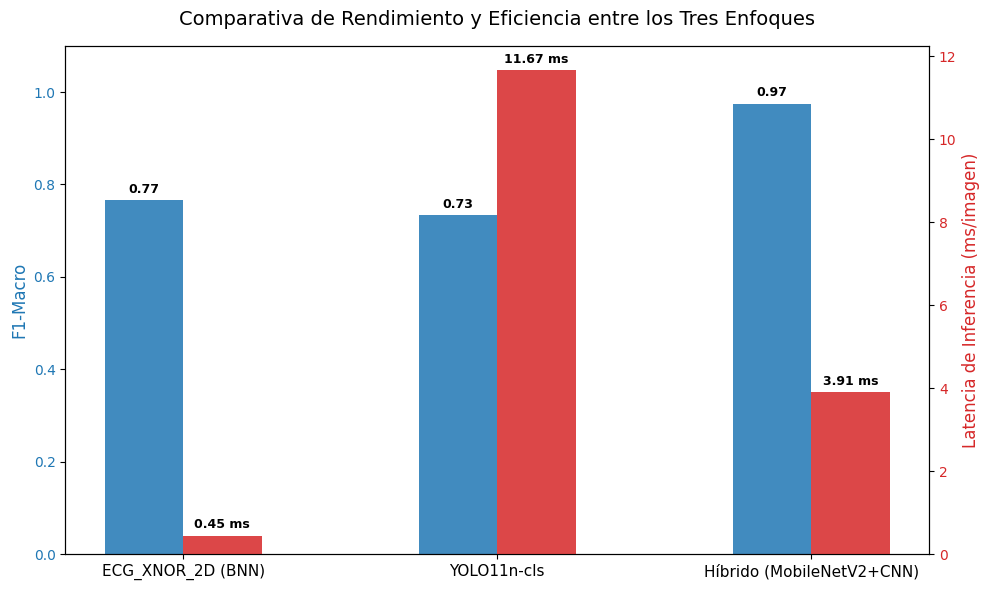

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Datos promedio obtenidos del entrenamiento con 5 semillas
modelos = ['ECG_XNOR_2D (BNN)', 'YOLO11n-cls', 'Híbrido (MobileNetV2+CNN)']
f1_scores = [0.7657, 0.7332, 0.9749]
latencias = [0.4476, 11.6729, 3.9118] # en milisegundos
tiempos_train = [113.75, 74.88, 333.47] # en segundos

x = np.arange(len(modelos))
width = 0.25

fig, ax1 = plt.subplots(figsize=(10, 6))

# Eje 1: F1-Macro y Tiempo de entrenamiento
color = 'tab:blue'
rects1 = ax1.bar(x - width/2, f1_scores, width, label='F1-Macro (Precisión)', color='#1f77b4', alpha=0.85)
ax1.set_ylabel('F1-Macro', color=color, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Eje 2: Latencia de Inferencia
ax2 = ax1.twinx()
color = 'tab:red'
rects2 = ax2.bar(x + width/2, latencias, width, label='Latencia (ms/img)', color='#d62728', alpha=0.85)
ax2.set_ylabel('Latencia de Inferencia (ms/imagen)', color=color, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color)

# Títulos y formato
plt.title('Comparativa de Rendimiento y Eficiencia entre los Tres Enfoques', fontsize=14, pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(modelos, fontsize=11)

# Añadir etiquetas de valor
def autolabel(rects, ax, suffix=""):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}{suffix}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 pt vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1, ax1)
autolabel(rects2, ax2, " ms")

fig.tight_layout()
plt.show()

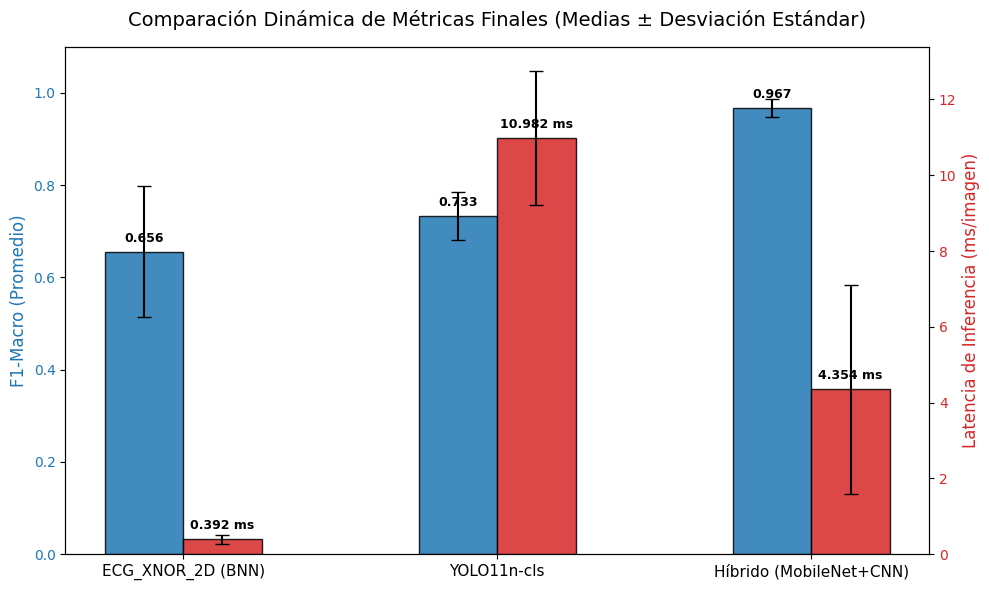

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carga dinámica y automática directa desde los archivos CSV guardados en Drive
csv_hybrid = "/content/drive/MyDrive/ecg_models/resultados_hybrid_5_semillas.csv"
csv_bnn = "/content/drive/MyDrive/ecg_models/resultados_bnn_5_semillas.csv"
csv_yolo = "/content/drive/MyDrive/ecg_models/resultados_yolo_5_semillas.csv"

df_h = pd.read_csv(csv_hybrid)
df_b = pd.read_csv(csv_bnn)
df_y = pd.read_csv(csv_yolo)

modelos = ['ECG_XNOR_2D (BNN)', 'YOLO11n-cls', 'Híbrido (MobileNet+CNN)']

f1_means = [df_b['f1_macro'].mean(), df_y['f1_macro'].mean(), df_h['f1_macro'].mean()]
f1_stds = [df_b['f1_macro'].std(), df_y['f1_macro'].std(), df_h['f1_macro'].std()]

lat_means = [df_b['latencia_ms_por_img'].mean(), df_y['latencia_ms_por_img'].mean(), df_h['latencia_ms_por_img'].mean()]
lat_stds = [df_b['latencia_ms_por_img'].std(), df_y['latencia_ms_por_img'].std(), df_h['latencia_ms_por_img'].std()]

x = np.arange(len(modelos))
width = 0.25

fig, ax1 = plt.subplots(figsize=(10, 6))

# Gráfico de barras para la precisión (F1-Macro) con su desviación estándar como barra de error
color = 'tab:blue'
rects1 = ax1.bar(x - width/2, f1_means, width, yerr=f1_stds, capsize=5,
                 label='F1-Macro Mean', color='#1f77b4', alpha=0.85, edgecolor='black')
ax1.set_ylabel('F1-Macro (Promedio)', color=color, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Gráfico de barras para la Latencia en milisegundos con barras de error
ax2 = ax1.twinx()
color = 'tab:red'
rects2 = ax2.bar(x + width/2, lat_means, width, yerr=lat_stds, capsize=5,
                 label='Latencia Mean', color='#d62728', alpha=0.85, edgecolor='black')
ax2.set_ylabel('Latencia de Inferencia (ms/imagen)', color=color, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparación Dinámica de Métricas Finales (Medias ± Desviación Estándar)', fontsize=14, pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(modelos, fontsize=11)

def autolabel(rects, ax, suffix=""):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}{suffix}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 5),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1, ax1)
autolabel(rects2, ax2, " ms")

fig.tight_layout()
plt.show()